# RNN-Based Intelligent Lost and Found Item Matching System

This notebook builds a **Bi-LSTM (Bidirectional Long Short-Term Memory)** model using **PyTorch** to predict whether a *lost* item report and a *found* item report refer to the **same item**.

**Multi-GPU:** Configured to utilize **2x NVIDIA T4 GPUs** on Kaggle via `nn.DataParallel`.

---

**Dataset:** `lost_found_dataset_realistic_metadata_30k.csv`  
**Columns:** `item_id`, `lost_or_found`, `item_name`, `description`, `color`, `brand`, `location`, `user`, `timestamp`  
**Records:** 30,000 (15,000 lost + 15,000 found)  
**Task:** Binary classification — Match (1) vs No Match (0)


## 1. Install and Import Dependencies

In [ ]:
# Install required packages (uncomment if needed)
# !pip install torch pandas numpy scikit-learn matplotlib seaborn

In [1]:
import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

from collections import Counter

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)  # seed all GPUs

# ---------- Multi-GPU Setup for Kaggle (2x T4) ----------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()
print(f'Using device: {device}')
print(f'Number of GPUs available: {NUM_GPUS}')
if NUM_GPUS > 0:
    for i in range(NUM_GPUS):
        print(f'  GPU {i}: {torch.cuda.get_device_name(i)}')


Using device: cuda
Number of GPUs available: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


## 2. Load and Inspect the Dataset

In [2]:
df = pd.read_csv(r'/kaggle/input/datasets/bmuthukumar07/lost-found-dataset/lost_found_dataset_realistic_metadata_30k.csv')

print(f'Shape: {df.shape}')
print(f'\nColumns: {list(df.columns)}')
print(f'\nData types:\n{df.dtypes}')
print(f'\nMissing values:\n{df.isnull().sum()}')
df.head(10)

Shape: (30000, 9)

Columns: ['item_id', 'lost_or_found', 'item_name', 'description', 'color', 'brand', 'location', 'user', 'timestamp']

Data types:
item_id           int64
lost_or_found    object
item_name        object
description      object
color            object
brand            object
location         object
user             object
timestamp        object
dtype: object

Missing values:
item_id             0
lost_or_found       0
item_name           0
description         0
color               0
brand            1652
location            0
user                0
timestamp           0
dtype: int64


,item_id,lost_or_found,item_name,description,color,brand,location,user,timestamp
0,1,lost,Keychain,"Can't find my keychain (yellow), has a sticker.",yellow,Milton,Garden,Suma,2025-09-23 17:34:15
1,2,found,Keychain,"Picked up yellow keychain, belongs to someone.",yellow,Milton,Garden,Yash,2025-10-16 17:34:15
2,3,lost,Marker,"Missing marker (yellow), last seen near campus.",yellow,HP,Gym,Ananya,2025-11-06 17:34:15
3,4,found,Marker,Found a yellow marker with minor marks.,yellow,HP,Gym,Arjun,2025-10-07 17:34:15
4,5,lost,Notebook,L0st notebook (brown) bro pls help find.,brown,Samsung,Study Hall,Manoj,2025-11-24 17:34:15
5,6,found,Notebook,Notebook (brown) discovered near walkway.,brown,Samsung,Study Hall,Pooja,2025-10-10 17:34:15
6,7,lost,Bag,"I lost my grey bag, has scratches near the edge.",grey,Casio,Parking Area,Siri,2025-11-15 17:34:15
7,8,found,Bag,Found sum bag (grey) lol not sure whose.,grey,Casio,Parking Area,Manoj,2025-09-03 17:34:15
8,9,lost,Power Bank,"Can't find my power bank (silver), has a sticker.",silver,Samsung,Corridor,Ananya,2025-08-19 17:34:15
9,10,found,Power Bank,Found sum power bank (silver) lol not sure whose.,silver,Samsung,Corridor,Ananya,2025-11-13 17:34:15


In [3]:
# Distribution of lost vs found
print('Lost vs Found distribution:')
print(df['lost_or_found'].value_counts())

print(f'\nUnique item names: {df["item_name"].nunique()}')
print(f'Unique colors: {df["color"].nunique()}')
print(f'Unique brands: {df["brand"].nunique()}')
print(f'Unique locations: {df["location"].nunique()}')

print(f'\nSample item names: {df["item_name"].unique()[:15]}')
print(f'Sample colors: {df["color"].unique()[:10]}')
print(f'Sample brands: {df["brand"].unique()[:10]}')
print(f'Sample locations: {df["location"].unique()[:10]}')

Lost vs Found distribution:
lost_or_found
lost     15000
found    15000
Name: count, dtype: int64

Unique item names: 31
Unique colors: 11
Unique brands: 17
Unique locations: 19

Sample item names: ['Keychain' 'Marker' 'Notebook' 'Bag' 'Power Bank' 'Laptop Bag' 'Textbook'
 'Tumbler' 'Wallet' 'Calculator' 'Pencil Box' 'Mobile Case' 'Pen Drive'
 'Flask' 'ID Card']
Sample colors: ['yellow' 'brown' 'grey' 'silver' 'black' 'white' 'blue' 'pink' 'red'
 'purple']
Sample brands: ['Milton' 'HP' 'Samsung' 'Casio' 'Cello' 'Adidas' 'Puma' 'Nike' 'Dell' nan]
Sample locations: ['Garden' 'Gym' 'Study Hall' 'Parking Area' 'Corridor' 'Main Gate'
 'Bus Stop' 'Sports Ground' 'Admin Block' 'Auditorium']


## 3. Separate Lost and Found Records

In [5]:
lost_df = df[df['lost_or_found'] == 'lost'].reset_index(drop=True)
found_df = df[df['lost_or_found'] == 'found'].reset_index(drop=True)

print(f'Lost records:  {len(lost_df)}')
print(f'Found records: {len(found_df)}')

print('\n--- Sample LOST record ---')
print(lost_df.iloc[0][['item_name', 'description', 'color', 'brand', 'location']])

print('\n--- Sample FOUND record ---')
print(found_df.iloc[0][['item_name', 'description', 'color', 'brand', 'location']])

Lost records:  15000
Found records: 15000

--- Sample LOST record ---
item_name                                             Keychain
description    Can't find my keychain (yellow), has a sticker.
color                                                   yellow
brand                                                   Milton
location                                                Garden
Name: 0, dtype: object

--- Sample FOUND record ---
item_name                                            Keychain
description    Picked up yellow keychain, belongs to someone.
color                                                  yellow
brand                                                  Milton
location                                               Garden
Name: 0, dtype: object


## 4. Create Combined Text Feature

We combine `description`, `item_name`, `color`, `brand`, and `location` into a single text string for each record. This gives the model richer context for matching.

In [6]:
def create_combined_text(row):
    """Combine description with structured attributes into a single text."""
    parts = [
        str(row['description']),
        f"item {row['item_name']}",
        f"color {row['color']}",
        f"brand {row['brand']}",
        f"location {row['location']}"
    ]
    return ' '.join(parts)

lost_df['combined_text'] = lost_df.apply(create_combined_text, axis=1)
found_df['combined_text'] = found_df.apply(create_combined_text, axis=1)

print('Sample combined text (LOST):')
print(lost_df['combined_text'].iloc[0])
print('\nSample combined text (FOUND):')
print(found_df['combined_text'].iloc[0])

Sample combined text (LOST):
Can't find my keychain (yellow), has a sticker. item Keychain color yellow brand Milton location Garden

Sample combined text (FOUND):
Picked up yellow keychain, belongs to someone. item Keychain color yellow brand Milton location Garden


## 5. Create Lost-Found Pairs (Match=1, No Match=0)

**Matching logic:**  
A lost and found record are considered a *match* if they share the **same `item_name`, `color`, and `brand`**.

We create:
- **Positive pairs (Match=1):** Lost-Found records sharing item_name + color + brand
- **Negative pairs (Match=0):** Randomly paired lost-found records that differ in at least one key attribute

Target: ~12,000 total pairs (balanced).

In [7]:
# ---------- Create a matching key from (item_name, color, brand) ----------
lost_df['match_key'] = (
    lost_df['item_name'].str.lower() + '|' +
    lost_df['color'].str.lower() + '|' +
    lost_df['brand'].str.lower()
)
found_df['match_key'] = (
    found_df['item_name'].str.lower() + '|' +
    found_df['color'].str.lower() + '|' +
    found_df['brand'].str.lower()
)

# ---------- Positive pairs (Match = 1) ----------
positive_pairs = []

# Group found items by their match_key for fast lookup
found_groups = found_df.groupby('match_key')

for idx, lost_row in lost_df.iterrows():
    key = lost_row['match_key']
    if key in found_groups.groups:
        # Pick one random found item with the same key
        candidates = found_groups.get_group(key)
        found_row = candidates.sample(1, random_state=SEED + idx).iloc[0]
        positive_pairs.append({
            'lost_text': lost_row['combined_text'],
            'found_text': found_row['combined_text'],
            'label': 1
        })

print(f'Positive pairs generated: {len(positive_pairs)}')

# ---------- Negative pairs (No Match = 0) ----------
num_negatives = len(positive_pairs)
negative_pairs = []

found_texts = found_df['combined_text'].values
found_match_keys = found_df['match_key'].values

random.seed(SEED)
attempts = 0
max_attempts = num_negatives * 5

while len(negative_pairs) < num_negatives and attempts < max_attempts:
    lost_idx = random.randint(0, len(lost_df) - 1)
    found_idx = random.randint(0, len(found_df) - 1)
    
    # Ensure the pair does NOT match on key attributes
    if lost_df.iloc[lost_idx]['match_key'] != found_match_keys[found_idx]:
        negative_pairs.append({
            'lost_text': lost_df.iloc[lost_idx]['combined_text'],
            'found_text': found_texts[found_idx],
            'label': 0
        })
    attempts += 1

print(f'Negative pairs generated: {len(negative_pairs)}')

# ---------- Combine into a single DataFrame ----------
pairs_df = pd.DataFrame(positive_pairs + negative_pairs)
pairs_df = pairs_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f'\nTotal pairs: {len(pairs_df)}')
print(f'Label distribution:\n{pairs_df["label"].value_counts()}')

Positive pairs generated: 13920
Negative pairs generated: 13920

Total pairs: 27840
Label distribution:
label
0    13920
1    13920
Name: count, dtype: int64


In [8]:
# Preview some pairs
print('=' * 80)
for i in range(4):
    row = pairs_df.iloc[i]
    label_str = 'MATCH' if row['label'] == 1 else 'NO MATCH'
    print(f'\nPair {i+1} [{label_str}]')
    print(f'  LOST:  {row["lost_text"][:100]}...')
    print(f'  FOUND: {row["found_text"][:100]}...')
    print('-' * 80)


Pair 1 [NO MATCH]
  LOST:  Can't find my umbrella (green), has a sticker. item Umbrella color green brand Milton location Bus S...
  FOUND: Picked up pink clipboard, belongs to someone. item Clipboard color pink brand WildHorn location Libr...
--------------------------------------------------------------------------------

Pair 2 [MATCH]
  LOST:  L0st notepad (pink) bro pls help find. item Notepad color pink brand Pearson location Cricket Ground...
  FOUND: Picked up pink notepad, belongs to someone. item Notepad color pink brand Pearson location Classroom...
--------------------------------------------------------------------------------

Pair 3 [MATCH]
  LOST:  btw Can't find my calculator (white), has a sticker. item Calculator color white brand Lenovo locati...
  FOUND: Object does not match any typical campus items. item Calculator color white brand Lenovo location Sp...
--------------------------------------------------------------------------------

Pair 4 [NO MATCH]
  LOST:  

## 6. Text Preprocessing

In [9]:
def clean_text(text):
    """Basic text cleaning: lowercase, remove special chars, normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)      # keep only alphanumeric + spaces
    text = re.sub(r'\s+', ' ', text).strip()        # collapse multiple spaces
    return text

pairs_df['lost_clean'] = pairs_df['lost_text'].apply(clean_text)
pairs_df['found_clean'] = pairs_df['found_text'].apply(clean_text)

print('Cleaned text sample:')
print(pairs_df[['lost_clean', 'found_clean']].head(3))

Cleaned text sample:
                                          lost_clean  \
0  can t find my umbrella green has a sticker ite...   
1  l0st notepad pink bro pls help find item notep...   
2  btw can t find my calculator white has a stick...   

                                         found_clean  
0  picked up pink clipboard belongs to someone it...  
1  picked up pink notepad belongs to someone item...  
2  object does not match any typical campus items...  


## 7. Build Vocabulary, Tokenize, and Pad Sequences

In [10]:
# ---------- Build vocabulary from all text ----------
all_texts = pd.concat([pairs_df['lost_clean'], pairs_df['found_clean']])
word_counts = Counter()
for text in all_texts:
    word_counts.update(text.split())

# Reserve 0 = <PAD>, 1 = <UNK>
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, count in word_counts.most_common():
    if count >= 2:  # minimum frequency threshold
        vocab[word] = len(vocab)

vocab_size = len(vocab)
print(f'Vocabulary size: {vocab_size}')
print(f'Sample vocab entries: {dict(list(vocab.items())[:10])}')

Vocabulary size: 1386
Sample vocab entries: {'<PAD>': 0, '<UNK>': 1, 'item': 2, 'color': 3, 'brand': 4, 'location': 5, 'my': 6, 'found': 7, 'near': 8, 'a': 9}


In [11]:
# ---------- Tokenize: convert words to integer indices ----------
def text_to_indices(text, vocab):
    """Convert a cleaned text string to a list of vocabulary indices."""
    return [vocab.get(word, vocab['<UNK>']) for word in text.split()]

pairs_df['lost_tokens'] = pairs_df['lost_clean'].apply(lambda x: text_to_indices(x, vocab))
pairs_df['found_tokens'] = pairs_df['found_clean'].apply(lambda x: text_to_indices(x, vocab))

# ---------- Determine max sequence length ----------
all_lengths = pairs_df['lost_tokens'].apply(len).tolist() + pairs_df['found_tokens'].apply(len).tolist()
MAX_LEN = int(np.percentile(all_lengths, 95))  # cover 95% of sequences
print(f'Max sequence length (95th percentile): {MAX_LEN}')
print(f'Mean length: {np.mean(all_lengths):.1f}, Max length: {np.max(all_lengths)}')

Max sequence length (95th percentile): 20
Mean length: 16.7, Max length: 24


In [12]:
# ---------- Pad / truncate sequences ----------
def pad_sequence(seq, max_len, pad_value=0):
    """Pad or truncate a sequence to max_len."""
    if len(seq) >= max_len:
        return seq[:max_len]
    return seq + [pad_value] * (max_len - len(seq))

pairs_df['lost_padded'] = pairs_df['lost_tokens'].apply(lambda x: pad_sequence(x, MAX_LEN))
pairs_df['found_padded'] = pairs_df['found_tokens'].apply(lambda x: pad_sequence(x, MAX_LEN))

print(f'Padded sequence example (first 15 tokens): {pairs_df["lost_padded"].iloc[0][:15]}')

Padded sequence example (first 15 tokens): [43, 41, 22, 6, 115, 21, 19, 9, 45, 2, 115, 3, 21, 4, 100]


## 8. Prepare PyTorch Dataset and DataLoaders

In [13]:
class LostFoundDataset(Dataset):
    """Custom Dataset for lost-found text pairs."""
    def __init__(self, lost_seqs, found_seqs, labels):
        self.lost_seqs = torch.tensor(lost_seqs, dtype=torch.long)
        self.found_seqs = torch.tensor(found_seqs, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.float32)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.lost_seqs[idx], self.found_seqs[idx], self.labels[idx]

In [15]:
# ---------- Train / Validation / Test split ----------
lost_seqs = np.array(pairs_df['lost_padded'].tolist())
found_seqs = np.array(pairs_df['found_padded'].tolist())
labels = pairs_df['label'].values

# 70% train, 15% val, 15% test
X_lost_train, X_lost_temp, X_found_train, X_found_temp, y_train, y_temp = train_test_split(
    lost_seqs, found_seqs, labels, test_size=0.3, random_state=SEED, stratify=labels
)
X_lost_val, X_lost_test, X_found_val, X_found_test, y_val, y_test = train_test_split(
    X_lost_temp, X_found_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

print(f'Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}')
print(f'Train label distribution: {Counter(y_train)}')

# Create datasets and dataloaders
BATCH_SIZE = 64

train_dataset = LostFoundDataset(X_lost_train, X_found_train, y_train)
val_dataset = LostFoundDataset(X_lost_val, X_found_val, y_val)
test_dataset = LostFoundDataset(X_lost_test, X_found_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Train: 19488 | Val: 4176 | Test: 4176
Train label distribution: Counter({np.int64(0): 9744, np.int64(1): 9744})


## 9. Build the Bi-LSTM Siamese Model

Architecture:
1. **Shared Embedding Layer** — converts token indices to dense vectors
2. **Shared Bi-LSTM** — encodes each text sequence into a fixed-size representation
3. **Combination** — concatenate + absolute difference of the two representations
4. **Classifier Head** — fully connected layers → sigmoid → match probability

In [16]:
class BiLSTMMatchingModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=128, num_layers=2, dropout=0.3):
        super(BiLSTMMatchingModel, self).__init__()
        
        # Shared embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # Shared Bi-LSTM encoder
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # Classifier head
        # Input: concat(lost_repr, found_repr, |lost_repr - found_repr|) -> 3 * (2*hidden_dim)
        classifier_input_dim = 3 * (2 * hidden_dim)
        self.classifier = nn.Sequential(
            nn.Linear(classifier_input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )
    
    def encode(self, x):
        """Encode a sequence through embedding + Bi-LSTM -> final hidden state."""
        embedded = self.embedding(x)               # (batch, seq_len, embed_dim)
        lstm_out, (h_n, _) = self.lstm(embedded)   # h_n: (num_layers*2, batch, hidden_dim)
        # Concatenate last layer forward and backward hidden states
        forward_hidden = h_n[-2]   # last layer forward
        backward_hidden = h_n[-1]  # last layer backward
        representation = torch.cat([forward_hidden, backward_hidden], dim=1)  # (batch, 2*hidden_dim)
        return representation
    
    def forward(self, lost_input, found_input):
        lost_repr = self.encode(lost_input)
        found_repr = self.encode(found_input)
        
        # Combine: [lost, found, |lost - found|]
        diff = torch.abs(lost_repr - found_repr)
        combined = torch.cat([lost_repr, found_repr, diff], dim=1)
        
        output = self.classifier(combined)
        return output.squeeze(1)

# Instantiate the model
model = BiLSTMMatchingModel(vocab_size=vocab_size).to(device)

# ---------- Wrap with DataParallel for multi-GPU ----------
if NUM_GPUS > 1:
    print(f'Using nn.DataParallel across {NUM_GPUS} GPUs')
    model = nn.DataParallel(model)

print(model)
print(f'\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}')


Using nn.DataParallel across 2 GPUs
DataParallel(
  (module): BiLSTMMatchingModel(
    (embedding): Embedding(1386, 64, padding_idx=0)
    (lstm): LSTM(64, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
    (classifier): Sequential(
      (0): Linear(in_features=768, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=128, out_features=64, bias=True)
      (4): ReLU()
      (5): Dropout(p=0.3, inplace=False)
      (6): Linear(in_features=64, out_features=1, bias=True)
      (7): Sigmoid()
    )
  )
)

Total parameters: 789,377


## 10. Train the Model

In [18]:
# Hyperparameters
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

In [19]:
# ---------- Training loop ----------
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
best_val_loss = float('inf')

for epoch in range(NUM_EPOCHS):
    # --- Training phase ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for lost_batch, found_batch, label_batch in train_loader:
        lost_batch = lost_batch.to(device)
        found_batch = found_batch.to(device)
        label_batch = label_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(lost_batch, found_batch)
        loss = criterion(outputs, label_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_loss += loss.item() * lost_batch.size(0)
        preds = (outputs >= 0.5).float()
        correct += (preds == label_batch).sum().item()
        total += label_batch.size(0)
    
    train_loss = running_loss / total
    train_acc = correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    
    # --- Validation phase ---
    model.eval()
    running_val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for lost_batch, found_batch, label_batch in val_loader:
            lost_batch = lost_batch.to(device)
            found_batch = found_batch.to(device)
            label_batch = label_batch.to(device)
            
            outputs = model(lost_batch, found_batch)
            loss = criterion(outputs, label_batch)
            
            running_val_loss += loss.item() * lost_batch.size(0)
            preds = (outputs >= 0.5).float()
            val_correct += (preds == label_batch).sum().item()
            val_total += label_batch.size(0)
    
    val_loss = running_val_loss / val_total
    val_acc = val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    
    scheduler.step(val_loss)
    
    # Save best model (unwrap DataParallel if needed)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model_to_save = model.module if hasattr(model, 'module') else model
        torch.save(model_to_save.state_dict(), 'best_model.pth')
    
    print(f'Epoch [{epoch+1:2d}/{NUM_EPOCHS}]  '
          f'Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}  '
          f'Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.4f}')

print(f'\nTraining complete! Best validation loss: {best_val_loss:.4f}')


Epoch [ 1/15]  Train Loss: 0.2292  Train Acc: 0.8797  Val Loss: 0.0290  Val Acc: 0.9926
Epoch [ 2/15]  Train Loss: 0.0267  Train Acc: 0.9918  Val Loss: 0.0427  Val Acc: 0.9911
Epoch [ 3/15]  Train Loss: 0.0144  Train Acc: 0.9962  Val Loss: 0.0097  Val Acc: 0.9969
Epoch [ 4/15]  Train Loss: 0.0060  Train Acc: 0.9985  Val Loss: 0.0044  Val Acc: 0.9993
Epoch [ 5/15]  Train Loss: 0.0065  Train Acc: 0.9980  Val Loss: 0.0018  Val Acc: 0.9990
Epoch [ 6/15]  Train Loss: 0.0047  Train Acc: 0.9988  Val Loss: 0.0111  Val Acc: 0.9978
Epoch [ 7/15]  Train Loss: 0.0048  Train Acc: 0.9986  Val Loss: 0.0123  Val Acc: 0.9976
Epoch [ 8/15]  Train Loss: 0.0059  Train Acc: 0.9983  Val Loss: 0.0010  Val Acc: 0.9998
Epoch [ 9/15]  Train Loss: 0.0025  Train Acc: 0.9994  Val Loss: 0.0027  Val Acc: 0.9990
Epoch [10/15]  Train Loss: 0.0015  Train Acc: 0.9996  Val Loss: 0.0050  Val Acc: 0.9990
Epoch [11/15]  Train Loss: 0.0016  Train Acc: 0.9996  Val Loss: 0.0044  Val Acc: 0.9990
Epoch [12/15]  Train Loss: 0.000

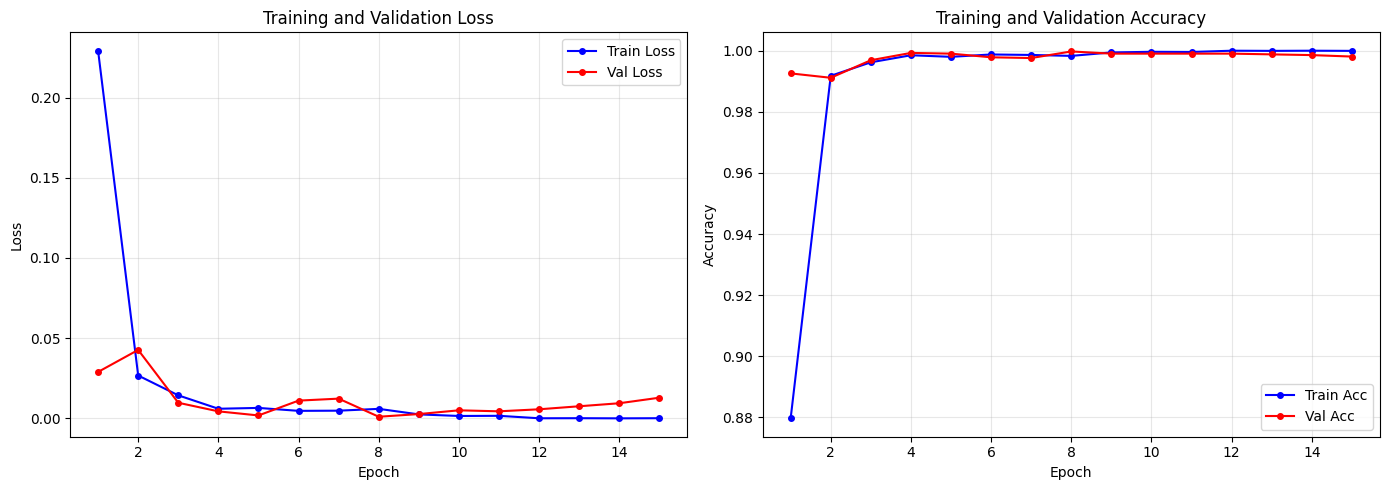

In [20]:
# ---------- Plot training curves ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(range(1, NUM_EPOCHS+1), train_losses, 'b-o', label='Train Loss', markersize=4)
axes[0].plot(range(1, NUM_EPOCHS+1), val_losses, 'r-o', label='Val Loss', markersize=4)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
axes[1].plot(range(1, NUM_EPOCHS+1), train_accuracies, 'b-o', label='Train Acc', markersize=4)
axes[1].plot(range(1, NUM_EPOCHS+1), val_accuracies, 'r-o', label='Val Acc', markersize=4)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Evaluate on Test Set

In [21]:
# Load the best model (unwrap DataParallel for clean loading)
model_for_eval = model.module if hasattr(model, 'module') else model
model_for_eval.load_state_dict(torch.load('best_model.pth', map_location=device))
model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for lost_batch, found_batch, label_batch in test_loader:
        lost_batch = lost_batch.to(device)
        found_batch = found_batch.to(device)
        
        outputs = model(lost_batch, found_batch)
        preds = (outputs >= 0.5).float()
        
        all_probs.extend(outputs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(label_batch.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)


In [22]:
# ---------- Metrics ----------
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print('=' * 50)
print('         TEST SET EVALUATION RESULTS')
print('=' * 50)
print(f'  Accuracy:  {accuracy:.4f}')
print(f'  Precision: {precision:.4f}')
print(f'  Recall:    {recall:.4f}')
print(f'  F1 Score:  {f1:.4f}')
print('=' * 50)

print('\nDetailed Classification Report:')
print(classification_report(all_labels, all_preds, target_names=['No Match (0)', 'Match (1)']))

         TEST SET EVALUATION RESULTS
  Accuracy:  0.9990
  Precision: 0.9986
  Recall:    0.9995
  F1 Score:  0.9990

Detailed Classification Report:
              precision    recall  f1-score   support

No Match (0)       1.00      1.00      1.00      2088
   Match (1)       1.00      1.00      1.00      2088

    accuracy                           1.00      4176
   macro avg       1.00      1.00      1.00      4176
weighted avg       1.00      1.00      1.00      4176



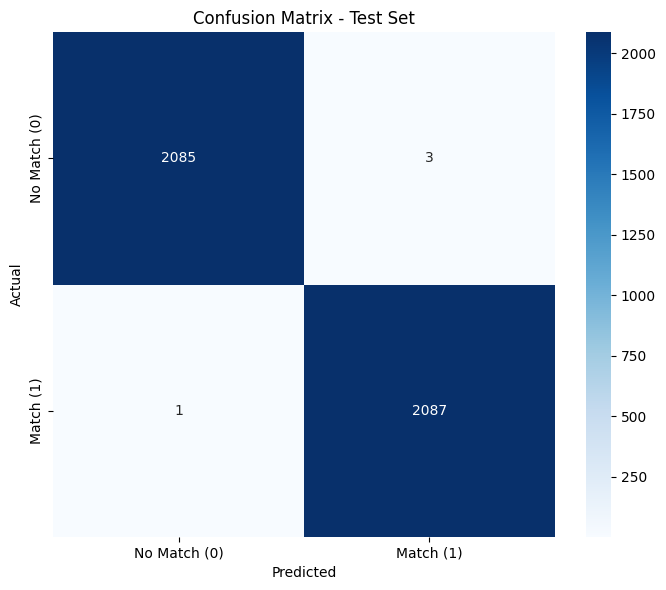

In [23]:
# ---------- Confusion Matrix ----------
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Match (0)', 'Match (1)'],
            yticklabels=['No Match (0)', 'Match (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Test Set')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Sample Predictions with Confidence Scores

In [24]:
# Show 10 sample predictions from the test set
print('=' * 100)
print('SAMPLE PREDICTIONS WITH CONFIDENCE SCORES')
print('=' * 100)

num_samples = 10
sample_indices = random.sample(range(len(all_labels)), min(num_samples, len(all_labels)))

for i, idx in enumerate(sample_indices):
    prob = all_probs[idx]
    pred = int(all_preds[idx])
    actual = int(all_labels[idx])
    
    status = 'Correct' if pred == actual else 'Wrong'
    pred_str = 'Match' if pred == 1 else 'No Match'
    actual_str = 'Match' if actual == 1 else 'No Match'
    
    print(f'\nSample {i+1}: {status}')
    print(f'  Prediction: {pred_str}  |  Actual: {actual_str}  |  Confidence: {prob:.4f}')
    print('-' * 100)

SAMPLE PREDICTIONS WITH CONFIDENCE SCORES

Sample 1: Correct
  Prediction: No Match  |  Actual: No Match  |  Confidence: 0.0000
----------------------------------------------------------------------------------------------------

Sample 2: Correct
  Prediction: No Match  |  Actual: No Match  |  Confidence: 0.0000
----------------------------------------------------------------------------------------------------

Sample 3: Correct
  Prediction: No Match  |  Actual: No Match  |  Confidence: 0.0000
----------------------------------------------------------------------------------------------------

Sample 4: Correct
  Prediction: Match  |  Actual: Match  |  Confidence: 1.0000
----------------------------------------------------------------------------------------------------

Sample 5: Correct
  Prediction: No Match  |  Actual: No Match  |  Confidence: 0.0000
----------------------------------------------------------------------------------------------------

Sample 6: Correct
  Predicti

## 13. Save Model and Vocabulary

In [25]:
# Save the final model (unwrap DataParallel to save clean weights)
model_to_save = model.module if hasattr(model, 'module') else model

torch.save({
    'model_state_dict': model_to_save.state_dict(),
    'vocab_size': vocab_size,
    'max_len': MAX_LEN,
    'embed_dim': 64,
    'hidden_dim': 128,
    'num_layers': 2,
}, 'lost_found_model_complete.pth')

# Save vocabulary
with open('vocabulary.json', 'w') as f:
    json.dump(vocab, f)

print('Model saved to: lost_found_model_complete.pth')
print('Best model saved to: best_model.pth')
print('Vocabulary saved to: vocabulary.json')
print(f'   Vocabulary size: {vocab_size}')
print(f'   Max sequence length: {MAX_LEN}')


Model saved to: lost_found_model_complete.pth
Best model saved to: best_model.pth
Vocabulary saved to: vocabulary.json
   Vocabulary size: 1386
   Max sequence length: 20


## 14. Inference Function - Test with New Descriptions

In [26]:
def predict_match(lost_description, found_description, model, vocab, max_len, device):
    """
    Predict whether a lost item description matches a found item description.
    
    Args:
        lost_description (str):  Free-text description of the lost item.
        found_description (str): Free-text description of the found item.
        model:  Trained BiLSTMMatchingModel (or DataParallel-wrapped).
        vocab:  Word-to-index dictionary.
        max_len: Maximum sequence length.
        device: torch device.
    
    Returns:
        dict with prediction, confidence, and label.
    """
    model.eval()
    
    # Clean
    lost_clean = clean_text(lost_description)
    found_clean = clean_text(found_description)
    
    # Tokenize
    lost_tokens = text_to_indices(lost_clean, vocab)
    found_tokens = text_to_indices(found_clean, vocab)
    
    # Pad
    lost_padded = pad_sequence(lost_tokens, max_len)
    found_padded = pad_sequence(found_tokens, max_len)
    
    # Convert to tensors
    lost_tensor = torch.tensor([lost_padded], dtype=torch.long).to(device)
    found_tensor = torch.tensor([found_padded], dtype=torch.long).to(device)
    
    # Predict (use underlying model for single-sample inference to avoid DataParallel overhead)
    inference_model = model.module if hasattr(model, 'module') else model
    with torch.no_grad():
        prob = inference_model(lost_tensor, found_tensor).item()
    
    prediction = 'Match' if prob >= 0.5 else 'No Match'
    
    return {
        'prediction': prediction,
        'confidence': round(prob, 4),
        'label': 1 if prob >= 0.5 else 0
    }


In [27]:
# ---------- Test Case 1: Should be a MATCH ----------
result1 = predict_match(
    lost_description='I lost my black wallet near the library item wallet color black brand Fastrack location Library',
    found_description='Found a black Fastrack wallet near the library entrance item wallet color black brand Fastrack location Library',
    model=model, vocab=vocab, max_len=MAX_LEN, device=device
)
print('Test 1 (Expected: Match)')
print(f'  Lost:  I lost my black wallet near the library')
print(f'  Found: Found a black Fastrack wallet near the library entrance')
print(f'  Result: {result1["prediction"]}  |  Confidence: {result1["confidence"]}')

print()

# ---------- Test Case 2: Should be NO MATCH ----------
result2 = predict_match(
    lost_description='Missing red Nike shoes from the gym item shoe color red brand Nike location Gym',
    found_description='Found a blue Samsung charger in the canteen item charger color blue brand Samsung location Canteen',
    model=model, vocab=vocab, max_len=MAX_LEN, device=device
)
print('Test 2 (Expected: No Match)')
print(f'  Lost:  Missing red Nike shoes from the gym')
print(f'  Found: Found a blue Samsung charger in the canteen')
print(f'  Result: {result2["prediction"]}  |  Confidence: {result2["confidence"]}')

print()

# ---------- Test Case 3: Partial overlap ----------
result3 = predict_match(
    lost_description='Lost my white Milton water bottle at the bus stop item water bottle color white brand Milton location Bus Stop',
    found_description='Found a white Milton bottle near the bus stop area item water bottle color white brand Milton location Bus Stop',
    model=model, vocab=vocab, max_len=MAX_LEN, device=device
)
print('Test 3 (Expected: Match)')
print(f'  Lost:  Lost my white Milton water bottle at the bus stop')
print(f'  Found: Found a white Milton bottle near the bus stop area')
print(f'  Result: {result3["prediction"]}  |  Confidence: {result3["confidence"]}')

print()

# ---------- Test Case 4: Same item type, different attributes ----------
result4 = predict_match(
    lost_description='Lost a pink Adidas bag in the hostel item bag color pink brand Adidas location Hostel Block A',
    found_description='Found a green Reebok bag in the parking lot item bag color green brand Reebok location Parking Area',
    model=model, vocab=vocab, max_len=MAX_LEN, device=device
)
print('Test 4 (Expected: No Match - same item type but different color/brand/location)')
print(f'  Lost:  Lost a pink Adidas bag in the hostel')
print(f'  Found: Found a green Reebok bag in the parking lot')
print(f'  Result: {result4["prediction"]}  |  Confidence: {result4["confidence"]}')

Test 1 (Expected: Match)
  Lost:  I lost my black wallet near the library
  Found: Found a black Fastrack wallet near the library entrance
  Result: Match  |  Confidence: 1.0

Test 2 (Expected: No Match)
  Lost:  Missing red Nike shoes from the gym
  Found: Found a blue Samsung charger in the canteen
  Result: No Match  |  Confidence: 0.0

Test 3 (Expected: Match)
  Lost:  Lost my white Milton water bottle at the bus stop
  Found: Found a white Milton bottle near the bus stop area
  Result: Match  |  Confidence: 1.0

Test 4 (Expected: No Match - same item type but different color/brand/location)
  Lost:  Lost a pink Adidas bag in the hostel
  Found: Found a green Reebok bag in the parking lot
  Result: No Match  |  Confidence: 0.0


## 15. Summary

| Component | Details |
|---|---|
| **Dataset** | `lost_found_dataset_realistic_metadata_30k.csv` - 30,000 records (15k lost + 15k found) |
| **Features Used** | `description`, `item_name`, `color`, `brand`, `location` |
| **Pair Generation** | Positive = same (item_name, color, brand); Negative = random mismatch |
| **Model** | Siamese Bi-LSTM (shared encoder) with concatenation + absolute-difference combiner |
| **Multi-GPU** | `nn.DataParallel` across 2x NVIDIA T4 GPUs on Kaggle |
| **Framework** | PyTorch |
| **Evaluation** | Accuracy, Precision, Recall, F1-Score, Confusion Matrix |
| **Saved Artifacts** | `best_model.pth`, `lost_found_model_complete.pth`, `vocabulary.json` |
